# Project : "Telecom - Churn Rate ML"
* Domain : Telecomunication 

# ML Model Building Path :
1. Define Business Case, Problem & Project Goal
2. Imports Laibrarys
3. Load and Validate the Data
4. Data CLeaning 
5. Exploratry Data Analysis(EDA)
6. 

# Business Case 
        "No-Churn Telecom is an established Telecom in Europe with more than a decade in Business. Due to new players in the market, telecom industry become very competitive and retaining customers becoming a challenge."

# Problem Statment 
        "In spite of No-Churn initiatives of reducing tariffs and promoting more offers, the churn rate ( percentage of customers migrating to competitors) is well above 10%."

# Project Goal 

* Understanding the variables that are influencing the customers to migrate.

* Creating Churn risk scores that can be indicative to drive retention campaigns.

* Introduce new predicting variable "CHURN-FLAG" with values YES(1) or NO(0) so that email campaigns with iucrative offers can be targeted to Churn YES customers.

# Imports Laibrarys 

In [79]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, precision_recall_curve)

import joblib

# Load and Validate the Data

In [80]:
df = pd.read_csv("D:\datasets\Internship_Projects\Client_Project\Telecom_Churn_Data.csv")
df.head()

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4.0,124962.0,44.0,45.0,-361.0,0.0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2.0,130556.0,62.0,39.0,5973.0,0.0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0.0,148828.0,49.0,24.0,193.0,1.0
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1.0,38722.0,80.0,25.0,9377.0,1.0
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2.0,55098.0,78.0,15.0,1393.0,0.0


In [81]:
# Select numerical columns
df.select_dtypes(include=['int64', 'float64']).columns

Index(['customer_id', 'age', 'pincode', 'num_dependents', 'estimated_salary',
       'calls_made', 'sms_sent', 'data_used', 'churn'],
      dtype='str')

In [82]:
# Select categorical columns
df.select_dtypes(include=['object']).columns

Index(['telecom_partner', 'gender', 'state', 'city', 'date_of_registration'], dtype='str')

In [83]:
# Dataset Shape
df.shape

(184209, 14)

In [84]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

In [85]:
# Dataset Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 184209 entries, 0 to 184208
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   customer_id           184209 non-null  int64  
 1   telecom_partner       184209 non-null  str    
 2   gender                184209 non-null  str    
 3   age                   184209 non-null  int64  
 4   state                 184209 non-null  str    
 5   city                  184209 non-null  str    
 6   pincode               184209 non-null  int64  
 7   date_of_registration  184209 non-null  str    
 8   num_dependents        184208 non-null  float64
 9   estimated_salary      184208 non-null  float64
 10  calls_made            184208 non-null  float64
 11  sms_sent              184208 non-null  float64
 12  data_used             184208 non-null  float64
 13  churn                 184208 non-null  float64
dtypes: float64(6), int64(3), str(5)
memory usage: 19.7 MB


In [86]:
# Dataset Description
df.describe(include='all')

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
count,184209.000000,184209,184209,184209.000000,184209,184209,184209.000000,184209,184208.000000,184208.000000,184208.000000,184208.000000,184208.000000,184208.000000
unique,NaN,4,2,NaN,28,6,NaN,923,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Reliance Jio,M,NaN,Karnataka,Hyderabad,NaN,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,46231,110304,NaN,6722,30819,NaN,200,NaN,NaN,NaN,NaN,NaN,NaN
mean,92105.000000,NaN,NaN,46.089996,NaN,NaN,549655.250417,NaN,1.996504,85033.173038,48.957309,23.952586,4990.401850,0.200567
std,53176.702206,NaN,NaN,16.436551,NaN,NaN,259787.686919,NaN,1.414474,37542.322288,29.441515,14.727613,2942.835665,0.400426
min,1.000000,NaN,NaN,18.000000,NaN,NaN,100006.000000,NaN,0.000000,20001.000000,-10.000000,-5.000000,-987.000000,0.000000
25%,46053.000000,NaN,NaN,32.000000,NaN,NaN,324608.000000,NaN,1.000000,52511.750000,24.000000,11.000000,2488.000000,0.000000
50%,92105.000000,NaN,NaN,46.000000,NaN,NaN,548212.000000,NaN,2.000000,85040.500000,49.000000,24.000000,4984.000000,0.000000
75%,138157.000000,NaN,NaN,60.000000,NaN,NaN,775187.000000,NaN,3.000000,117617.250000,74.000000,37.000000,7491.000000,0.000000


In [87]:
# Check the number of unique values in each column
df.nunique()

customer_id             184209
telecom_partner              4
gender                       2
age                         57
state                       28
city                         6
pincode                 166636
date_of_registration       923
num_dependents               5
estimated_salary         98472
calls_made                 119
sms_sent                    59
data_used                11789
churn                        2
dtype: int64

In [88]:
# Check for missing values
df.isnull().sum()[df.isnull().sum()>0]

num_dependents      1
estimated_salary    1
calls_made          1
sms_sent            1
data_used           1
churn               1
dtype: int64

In [89]:
# Check the distribution of the target variable
counts = df["churn"].value_counts(dropna=False)
pct = df["churn"].value_counts(normalize=True, dropna=False).mul(100).round(2)
print(pd.DataFrame({"count": counts, "percent": pct}))

        count  percent
churn                 
0.0    147262    79.94
1.0     36946    20.06
NaN         1     0.00


# Data Cleaning :

In [90]:
df.isnull().sum()[df.isnull().sum()>0]

num_dependents      1
estimated_salary    1
calls_made          1
sms_sent            1
data_used           1
churn               1
dtype: int64

In [91]:
# Drop Customer_id from original Data

df.drop(columns=['customer_id'],inplace=True)

In [92]:
df['num_dependents'] = df['num_dependents'].fillna(df['num_dependents'].median())
df['estimated_salary'] = df['estimated_salary'].fillna(df['estimated_salary'].median())
df['calls_made'] = df['calls_made'].fillna(df['calls_made'].median())
df['sms_sent'] = df['sms_sent'].fillna(df['sms_sent'].median())
df['data_used'] = df['data_used'].fillna(df['data_used'].median())

In [93]:
# 
df = df.dropna(subset=['churn'])

In [94]:
df.isnull().sum()[df.isnull().sum()>0]

Series([], dtype: int64)

# Exploratry Data Analysis (EDA) 

# Heatmape :
# Correlation of Veriables 

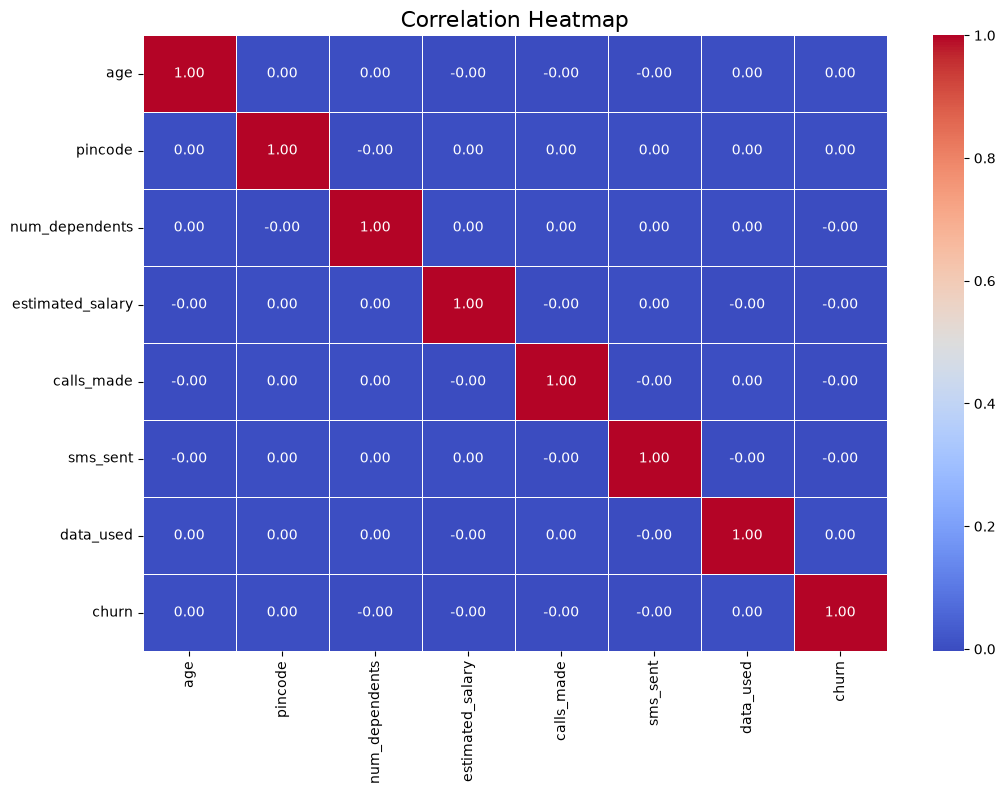

In [95]:
# Heatmape of Correlation Matrix
corr = df.select_dtypes(include=["number"]).corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap",fontsize=16)
plt.show()

# Bar Plot :
# Customer Churn Distribution 

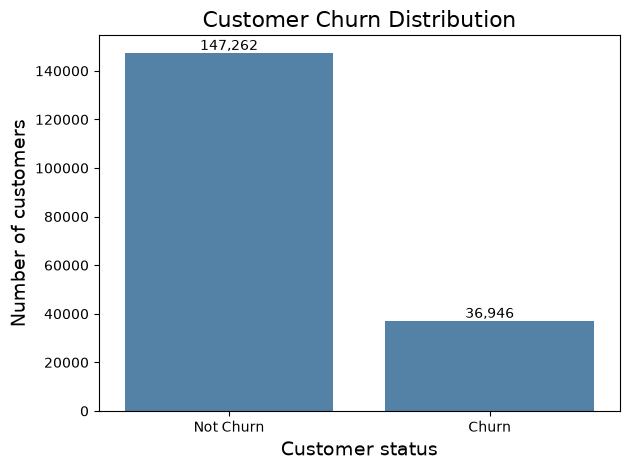

In [96]:
# Count each class, keeping both categories even if one has no rows
churn_counts = (
    df["churn"]
    .map({0: "Not Churn", 1: "Churn"})
    .value_counts()
    .reindex(["Not Churn", "Churn"], fill_value=0)
)

ax = sns.barplot(x=churn_counts.index, y=churn_counts.values, color="steelblue")

# Show counts above the bars
for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

ax.set_title("Customer Churn Distribution", fontsize=16)
ax.set_xlabel("Customer status", fontsize=14)
ax.set_ylabel("Number of customers", fontsize=14)
plt.tight_layout()
plt.show()

# Customer Distribution by Telecom Partner

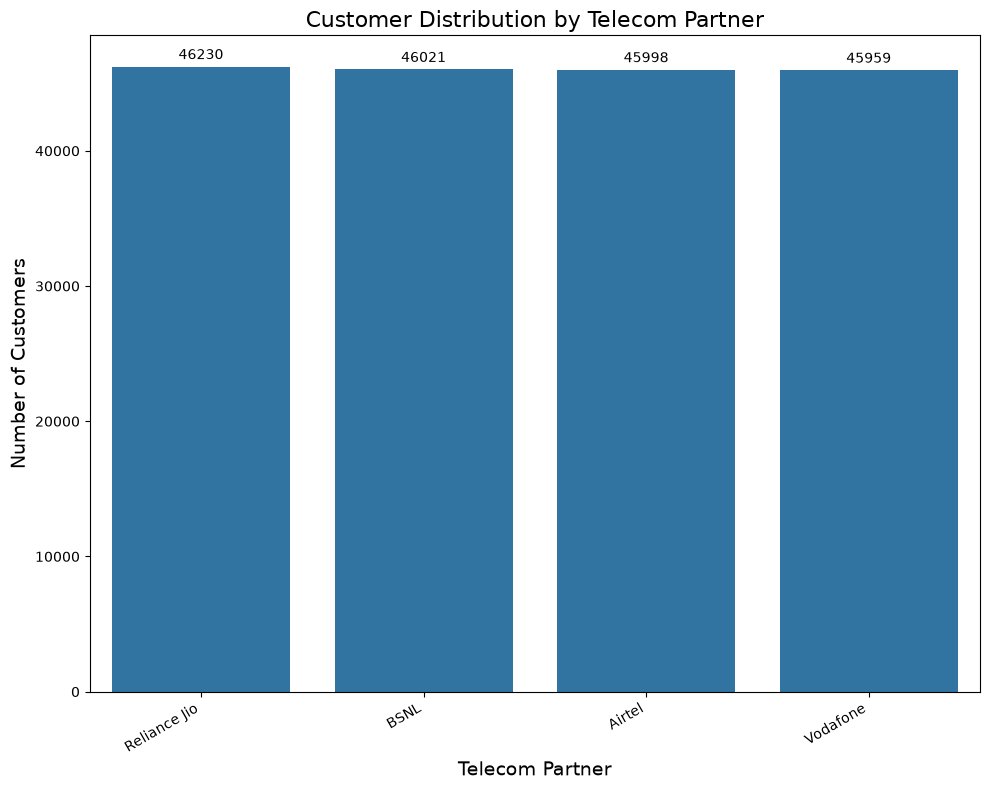

In [97]:
partner_counts = df["telecom_partner"].value_counts()

plt.figure(figsize=(10, 8))
ax = sns.barplot(
    x=partner_counts.index,
    y=partner_counts.values,
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_title("Customer Distribution by Telecom Partner",fontsize=16)
ax.set_xlabel("Telecom Partner",fontsize=14)
ax.set_ylabel("Number of Customers",fontsize=14)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

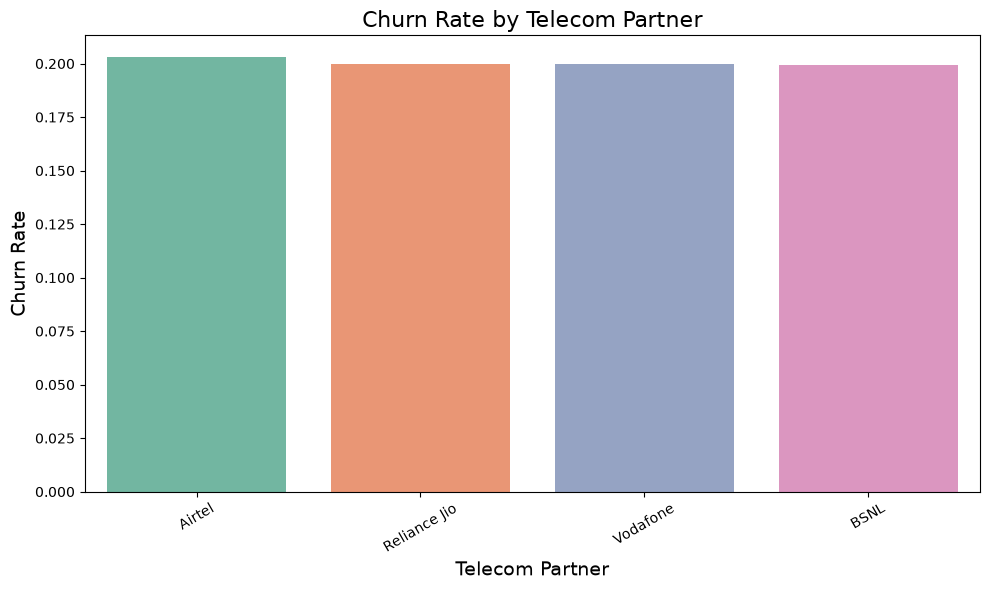

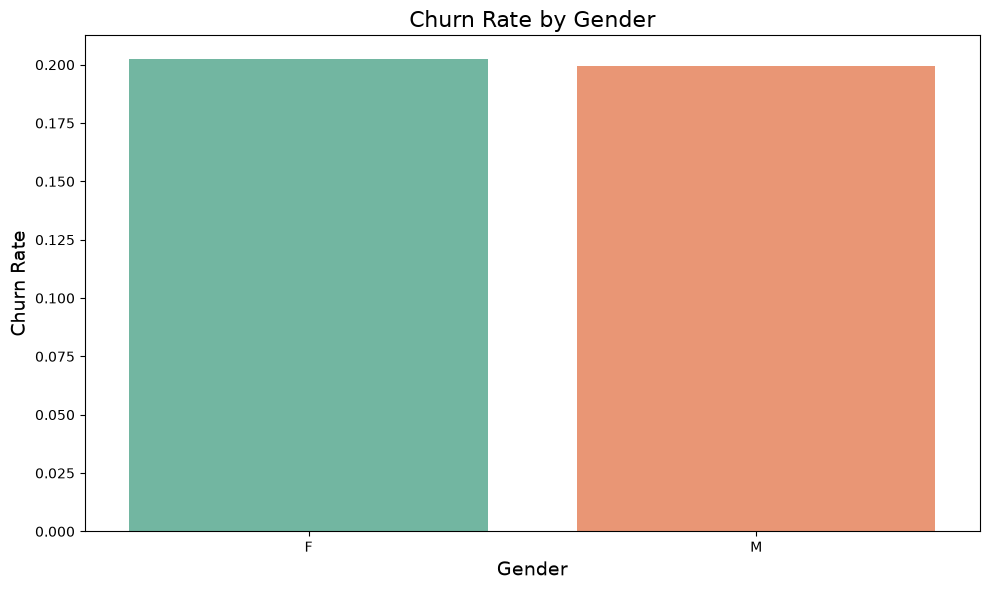

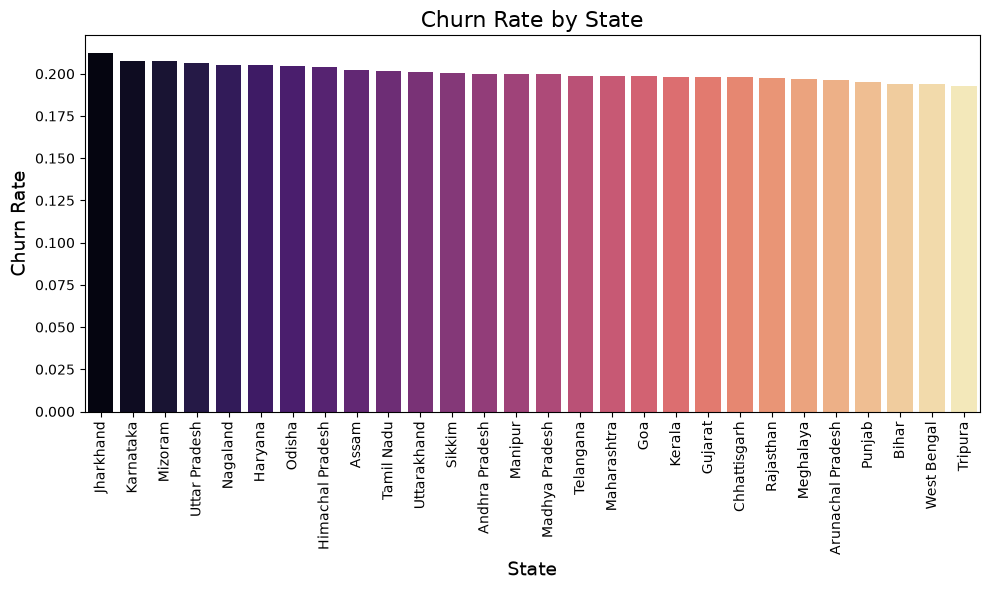

In [98]:
def churn_rate_plot(col, palette, rotation=0, figsize=(10, 6)):
    rate = df.groupby(col)["churn"].mean().sort_values(ascending=False)
    plt.figure(figsize=figsize)
    sns.barplot(x=rate.index, y=rate.values, hue=rate.index, palette=palette, legend=False)
    plt.title(f"Churn Rate by {col.replace('_', ' ').title()}", fontsize=16)
    plt.ylabel("Churn Rate", fontsize=14)
    plt.xlabel(col.replace("_", " ").title(), fontsize=14)
    plt.xticks(rotation=rotation)
    plt.tight_layout(); plt.show()

for col, pal, rot in [("telecom_partner", "Set2", 30), ("gender", "Set2", 0), ("state", "magma", 90)]:
    if col in df.columns:
        churn_rate_plot(col, pal, rot)

# Churn Rate Distribution By Gender

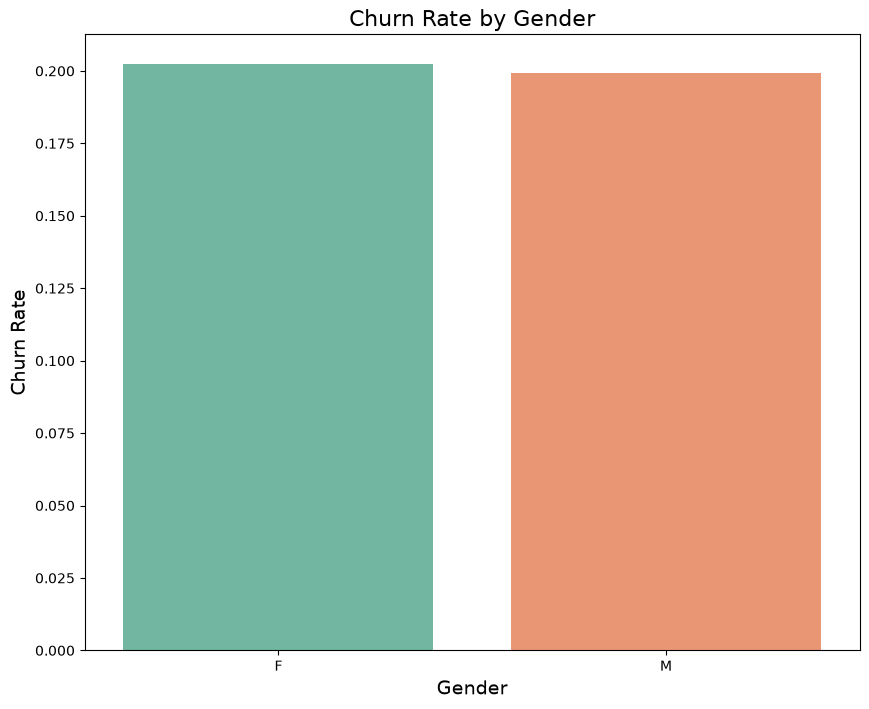

In [99]:
# Gender 
plt.figure(figsize=(10,8))
gender_churn = df.groupby("gender")["churn"].mean()
sns.barplot(x=gender_churn.index, y=gender_churn.values, palette="Set2")
plt.title("Churn Rate by Gender",fontsize=16)
plt.ylabel("Churn Rate",fontsize=14)
plt.xlabel("Gender",fontsize=14)
plt.xticks(rotation=0)
plt.show()

# Histogram & Boxplot :
* Numeric Features  Distribution 
* Compare Numeric Variables by Churn

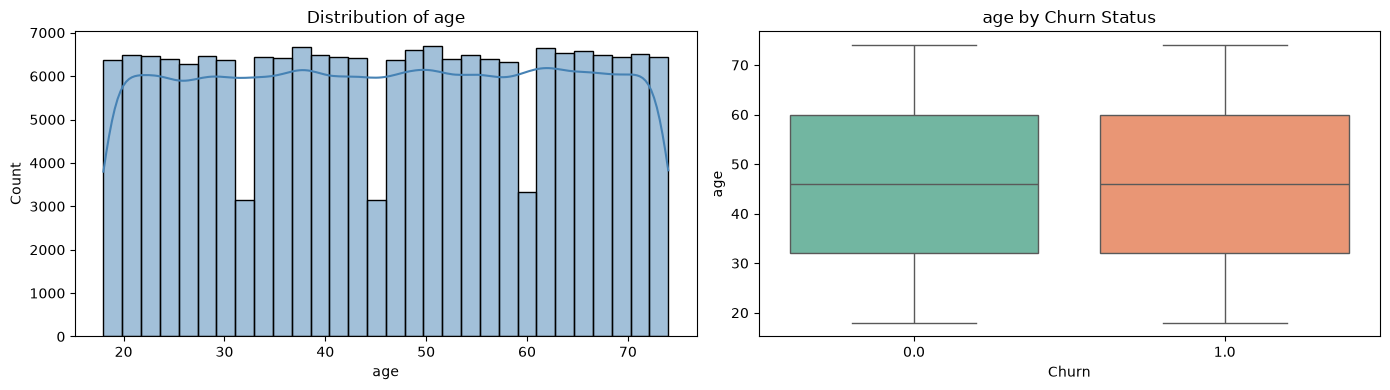

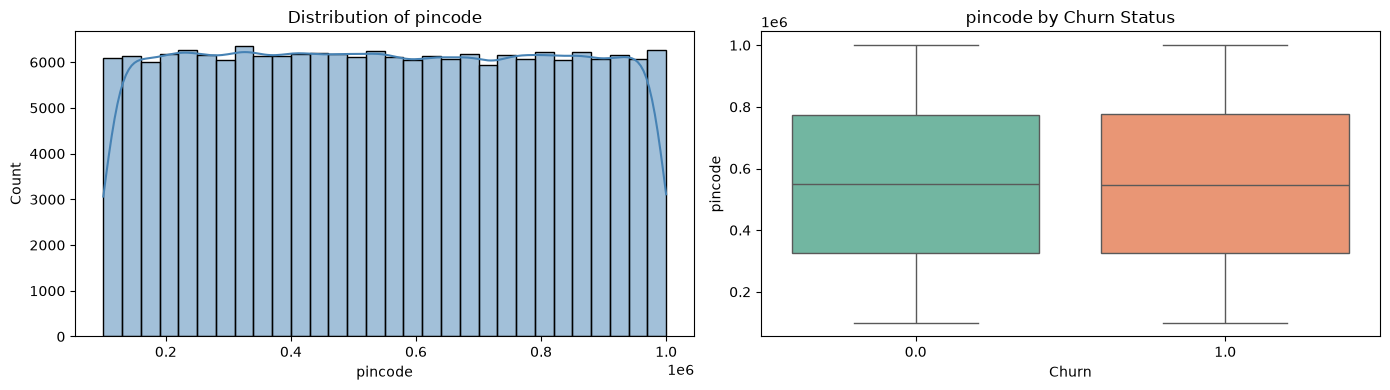

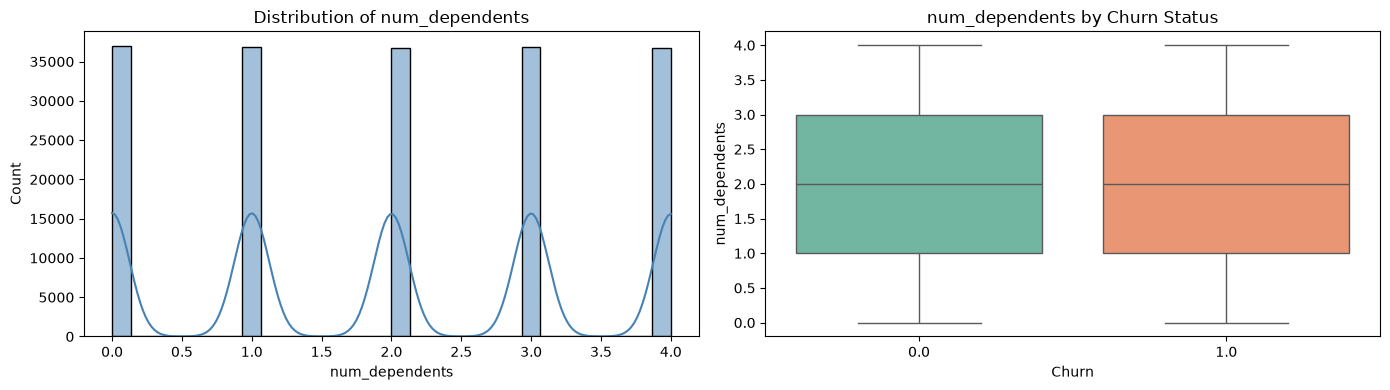

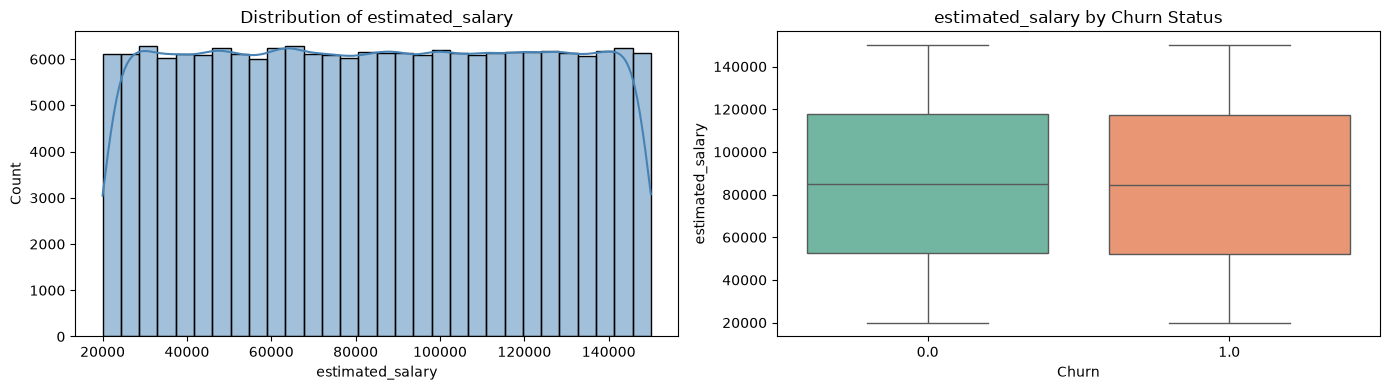

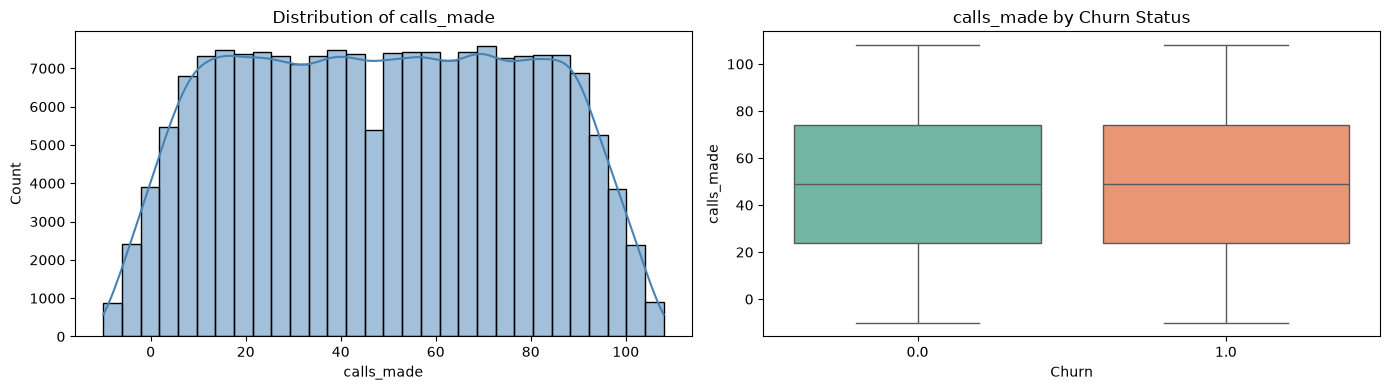

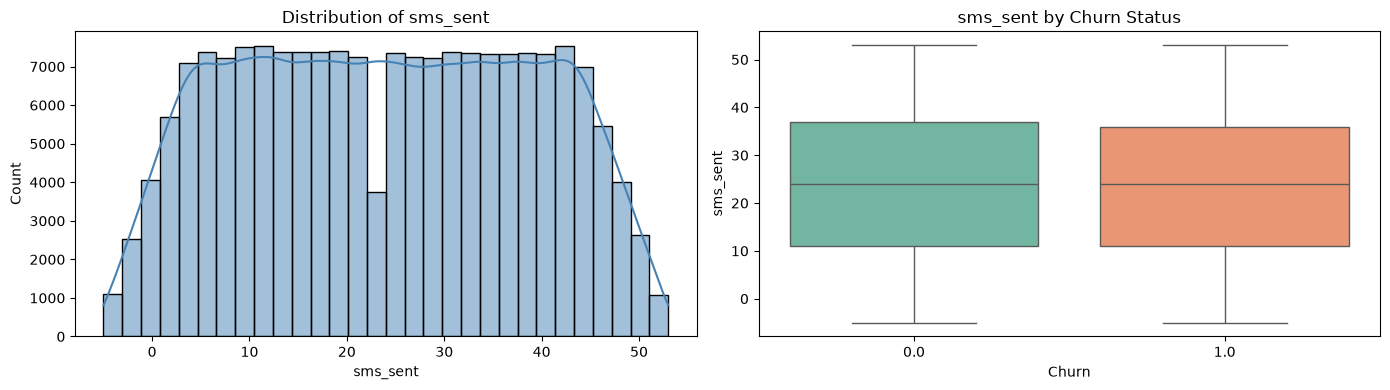

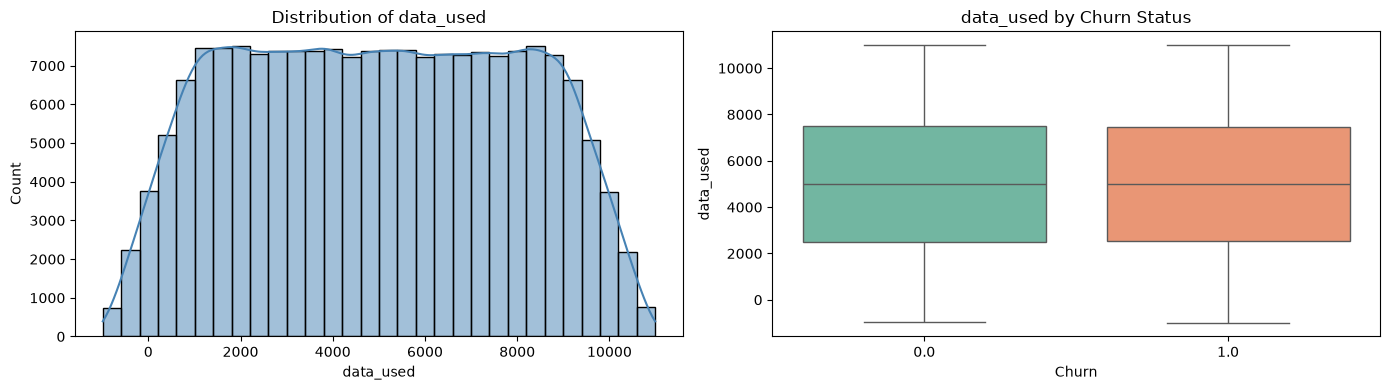

In [100]:
num_cols = df.select_dtypes(include="number").columns.drop("churn").tolist()

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.histplot(df[col], kde=True, bins=30, color="steelblue", ax=axes[0])
    axes[0].set_title(f"Distribution of {col}")
    sns.boxplot(x=df["churn"].astype(str), y=df[col], hue=df["churn"].astype(str),
                palette="Set2", legend=False, ax=axes[1])
    axes[1].set_title(f"{col} by Churn Status")
    axes[1].set_xlabel("Churn")
    plt.tight_layout(); plt.show()

In [101]:
# num_cols = df.select_dtypes(include=["number"]).columns.drop("churn")

# for col in num_cols:
#     plt.figure(figsize=(8,4))
#     sns.histplot(df[col], kde=True, bins=30, color="steelblue")
#     plt.title(f"Distribution of {col}")
#     plt.xlabel(col)
#     plt.ylabel("Frequency")
#     plt.show()

# Compare Numeric Variables by Churn :

In [102]:
# for col in num_cols:
#     plt.figure(figsize=(8,4))
#     sns.boxplot(x=df["churn"].astype(str), y=df[col], palette="Set2")
#     plt.title(f"{col} by Churn Status")
#     plt.xlabel("Churn")
#     plt.ylabel(col)
#     plt.show()

# Outlier check :

In [103]:
rows = []
for col in num_cols:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append({"feature": col, "outliers": n, "percent": round(n / len(df) * 100, 2)})
pd.DataFrame(rows).sort_values("outliers", ascending=False)

,feature,outliers,percent
0,age,0,0.0
1,pincode,0,0.0
2,num_dependents,0,0.0
3,estimated_salary,0,0.0
4,calls_made,0,0.0
5,sms_sent,0,0.0
6,data_used,0,0.0


# Feature Engineering :

In [104]:
from sklearn.preprocessing import FunctionTransformer

if {"calls_made", "sms_sent"}.issubset(df.columns):
    df["total_activity"] = df["calls_made"] + df["sms_sent"]
if {"data_used", "calls_made"}.issubset(df.columns):
    df["data_per_call"] = df["data_used"] / (df["calls_made"].clip(lower=0) + 1)

def inf_to_nan(X):
    X = np.asarray(X, dtype=float)
    return np.where(np.isinf(X), np.nan, X)

numeric_tf = Pipeline([
    ("inf", FunctionTransformer(inf_to_nan, feature_names_out="one-to-one")),
    ("impute", SimpleImputer(strategy="median")),
    ("cap", Winsorizer()),
    ("scale", StandardScaler()),
])

df = df.replace([np.inf, -np.inf], np.nan)
    
df.head()

,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn,total_activity,data_per_call
0,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4.0,124962.0,44.0,45.0,-361.0,0.0,89.0,-8.022222
1,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2.0,130556.0,62.0,39.0,5973.0,0.0,101.0,94.809524
2,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0.0,148828.0,49.0,24.0,193.0,1.0,73.0,3.860000
3,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1.0,38722.0,80.0,25.0,9377.0,1.0,105.0,115.765432
4,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2.0,55098.0,78.0,15.0,1393.0,0.0,93.0,17.632911


# Preprocessing Pipline :

In [105]:
x = df.drop(columns=["churn"])
y = df["churn"]

high_card = [c for c in x.select_dtypes(include='object').columns if x[c].nunique() > 50]
if high_card:
    print("Dropping high-cardinality columns:", high_card)
    x = x.drop(columns=high_card)
    
num_features = x.select_dtypes(include="number").columns.tolist()
cat_features = x.select_dtypes(include="object").columns.tolist()

x_train,x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", x_train.shape, "Test:", x_test.shape)
print("Churn rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

Dropping high-cardinality columns: ['date_of_registration']
Train: (147366, 13) Test: (36842, 13)
Churn rate train/test: 0.201 0.201


In [106]:
from sklearn.base import BaseEstimator, TransformerMixin

class Winsorizer(BaseEstimator, TransformerMixin):
    """Caps values at the IQR fences learned from the training data."""
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        q1, q3 = X.quantile(0.25), X.quantile(0.75)
        iqr = q3 - q1
        self.lower_ = (q1 - 1.5 * iqr).values
        self.upper_ = (q3 + 1.5 * iqr).values
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

numeric_tf = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("cap", Winsorizer()),
    ("scale", StandardScaler()),
])
categorical_tf = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_tf, num_features),
    ("cat", categorical_tf, cat_features),
])

# Model Building & Evaluation :

# Logistic Regression Model :

In [107]:
categorical_cols = x_train.select_dtypes(
    include=["object", "category"]
).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ],
    remainder="passthrough"
)

Log_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

Log_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[0.,1.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['telecom_partner','gender','age',...,'data_used','total_activity', 'data_per_call']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [108]:
# Evaluate the model on the test data
predictions = Log_model.predict(x_test)

print("Accuracy:",accuracy_score(y_test, predictions))
print("Precision:",precision_score(y_test, predictions))
print("Recall:", recall_score(y_test, predictions))
print("F1:",f1_score(y_test, predictions))
print("ROC-AUC:", roc_auc_score(y_test, predictions))
print("PR-AUC:",average_precision_score(y_test, predictions))

Accuracy: 0.5129200369143911
Precision: 0.19698013549201976
Recall: 0.46433888212207336
F1: 0.27661547143951304
ROC-AUC: 0.49472334049403166
PR-AUC: 0.19889727143386338


# Random Forest Model:

In [ ]:
Rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier",RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        n_jobs=-1,random_state=42
    ))
])
Rf_model.fit(x_train,y_train)

In [ ]:
# Evaluate the model on the test data
predictions = Rf_model.predict(x_test)

print("Accuracy:",accuracy_score(y_test, predictions))
print("Precision:",precision_score(y_test, predictions))
print("Recall:", recall_score(y_test, predictions))
print("F1:",f1_score(y_test, predictions))
print("ROC-AUC:", roc_auc_score(y_test, predictions))

# Gradient Boosting Model:

In [ ]:
Gb_model = Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",GradientBoostingClassifier(
        random_state=42
    ))
])
Gb_model.fit(x_test,y_test)

In [ ]:
# Evaluate the model on the test data
predictions = Gb_model.predict(x_test)

print("Accuracy:",accuracy_score(y_test, predictions))
print("Precision:",precision_score(y_test, predictions))
print("Recall:", recall_score(y_test, predictions))
print("F1:",f1_score(y_test, predictions))
print("ROC-AUC:", roc_auc_score(y_test, predictions))

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

fitted, results = {}, []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", clf)])
    pipe.fit(x_train, y_train)
    proba = pipe.predict_proba(x_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    fitted[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4).sort_values("PR-AUC", ascending=False)
results_df